# Surrogate modelling of history-matching quality

**Goal.** Every candidate set of history-matching parameters normally has to be checked with a full
reservoir simulation run. This notebook tests whether a cheap machine-learning *surrogate* can predict the
history-matching misfit (objective function) directly from the parameters, so that poor candidates can be
screened out before running the simulator.

**Data.** 92 ensemble members from an ensemble-smoother (ES-MDA) history-matching experiment in
tNavigator on a synthetic 3D black-oil model. For each member we know the 20 history-matching variables
(`M_ALPHA_0 … M_ALPHA_19`) and the resulting objective function `objfunc` (lower = better match).

**What is done here**
1. Exploratory look at the data.
2. Baselines (mean predictor, ridge regression) and XGBoost surrogates with a raw and a log-transformed target.
3. Evaluation on a single hold-out split *and* with repeated 5-fold cross-validation.
4. Ranking quality of the surrogate — the property that matters when it is used to screen candidates.
5. Parameter importance (permutation importance on held-out folds).
6. Computational speed-up compared with a full simulation run.

## 0. Setup

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from scipy.stats import spearmanr
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import (KFold, RepeatedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

SEED = 42
EPS = 0.01  # offset used in the log transform of the objective function
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("xgboost", xgb.__version__)

xgboost 2.1.4


## 1. Data

`data/es_mda_results.csv` — one row per ensemble member:

| column | meaning |
|---|---|
| `variant` | ensemble member id |
| `objfunc` | history-matching objective function (misfit between simulated and observed data; lower is better) |
| `field_*` | field-level simulated values exported together with the objective function (simulation **outputs**, not used as model inputs) |
| `M_ALPHA_0 … M_ALPHA_19` | the 20 history-matching variables of the ensemble workflow — the model **inputs** |

In [2]:
df = pd.read_csv(DATA_DIR / "es_mda_results.csv")
feature_cols = [f"M_ALPHA_{i}" for i in range(20)]
X = df[feature_cols].to_numpy()
y = df["objfunc"].to_numpy()

print(f"Ensemble members: {len(df)}, input parameters: {X.shape[1]}")
print(f"objfunc: min={y.min():.4f}, median={np.median(y):.4f}, max={y.max():.4f}")
df.head()

Ensemble members: 92, input parameters: 20
objfunc: min=0.0149, median=0.2127, max=1.4670


,variant,objfunc,field_avg_pressure_bar,field_oil_rate_sm3_per_day,field_water_rate_sm3_per_day,field_gas_rate_sm3_per_day,field_cum_water_injection_sm3,M_ALPHA_0,M_ALPHA_1,M_ALPHA_2,...,M_ALPHA_10,M_ALPHA_11,M_ALPHA_12,M_ALPHA_13,M_ALPHA_14,M_ALPHA_15,M_ALPHA_16,M_ALPHA_17,M_ALPHA_18,M_ALPHA_19
0,e2_v00000,0.173599,206.409882,623.716003,254.431915,41391.164062,0,0.893812,0.092048,0.041180,...,0.063052,0.000000,0.0,0.099226,0.036016,0.0,0.0,0.070009,0.0,0.053673
1,e2_v00001,0.091169,202.728882,601.072937,277.075012,55642.808594,0,0.750667,0.158378,0.000000,...,0.014539,0.007718,0.0,0.022921,0.782828,0.0,0.0,0.028953,0.0,0.104521
2,e2_v00002,0.257708,204.044983,619.487793,258.660156,39714.007812,0,0.799337,0.056771,0.016543,...,0.034518,0.080925,0.0,0.016420,0.040097,0.0,0.0,0.056845,0.0,0.000000
3,e2_v00003,0.379646,201.889969,601.127747,277.020172,45895.187500,0,0.832146,0.118736,0.143350,...,0.000000,0.007949,0.0,0.010662,0.000000,0.0,0.0,0.030019,0.0,0.000000
4,e2_v00004,0.701465,205.894363,628.244934,249.903015,44286.980469,0,0.002794,0.130104,0.089317,...,0.036531,0.000000,0.0,0.122127,0.076197,0.0,0.0,0.050968,0.0,0.076211


In [3]:
param_summary = pd.DataFrame({
    "min": df[feature_cols].min(),
    "max": df[feature_cols].max(),
    "share of zeros": (df[feature_cols] == 0).mean(),
}).round(3)
param_summary.T

,M_ALPHA_0,M_ALPHA_1,M_ALPHA_2,M_ALPHA_3,M_ALPHA_4,M_ALPHA_5,M_ALPHA_6,M_ALPHA_7,M_ALPHA_8,M_ALPHA_9,M_ALPHA_10,M_ALPHA_11,M_ALPHA_12,M_ALPHA_13,M_ALPHA_14,M_ALPHA_15,M_ALPHA_16,M_ALPHA_17,M_ALPHA_18,M_ALPHA_19
min,0.003,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,0.952,0.999,0.870,0.737,0.945,0.752,0.800,0.936,0.885,0.730,0.510,0.784,0.326,0.895,0.783,0.402,0.678,0.792,0.615,0.906
share of zeros,0.000,0.000,0.152,0.022,0.109,0.630,0.315,0.054,0.239,0.826,0.196,0.228,0.761,0.054,0.098,0.848,0.728,0.043,0.620,0.065


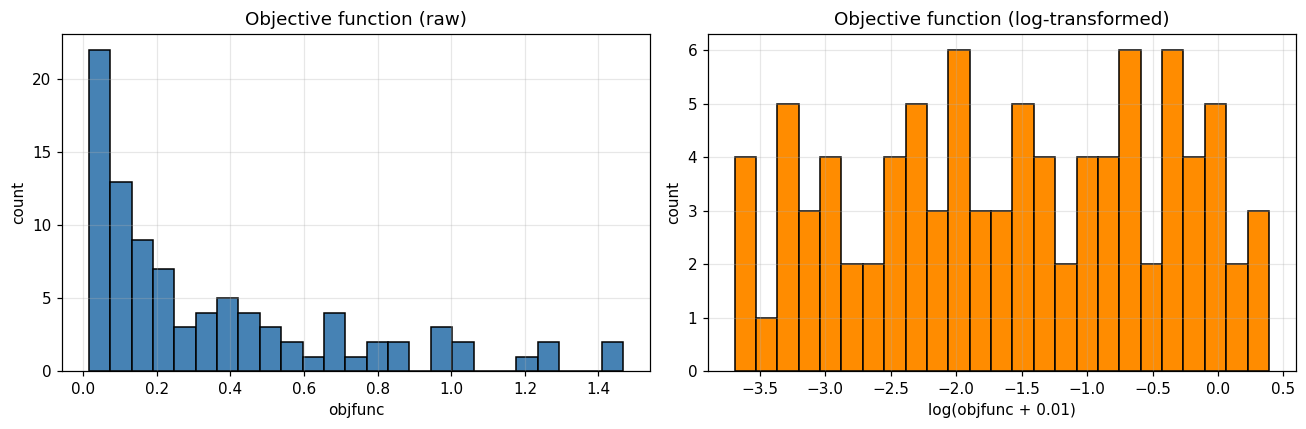

Skewness: raw = 1.29, log = -0.11


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins=25, color="steelblue", edgecolor="black")
axes[0].set(xlabel="objfunc", ylabel="count", title="Objective function (raw)")
axes[1].hist(np.log(y + EPS), bins=25, color="darkorange", edgecolor="black")
axes[1].set(xlabel=f"log(objfunc + {EPS})", ylabel="count", title="Objective function (log-transformed)")
plt.tight_layout()
fig.savefig(FIG_DIR / "objfunc_distribution.png", bbox_inches="tight")
plt.show()

print(f"Skewness: raw = {pd.Series(y).skew():.2f}, log = {pd.Series(np.log(y + EPS)).skew():.2f}")

The objective function is strongly right-skewed: a few very poor matches dominate the squared-error loss.
This motivates training a second model on `log(objfunc + 0.01)` and transforming predictions back.

## 2. Models

* **Mean predictor** — always predicts the training mean (sanity baseline, R² ≈ 0).
* **Ridge regression** — linear baseline on standardised inputs.
* **XGBoost, raw target** — gradient-boosted trees on `objfunc`.
* **XGBoost, log target** — the same model trained on `log(objfunc + 0.01)`; predictions are transformed back,
  so all metrics below are computed on the original `objfunc` scale.

The XGBoost hyper-parameters are the ones used in the original experiment and were not tuned further
(with only 92 samples, tuning on the same data would inflate the scores).

In [5]:
XGB_PARAMS = dict(n_estimators=300, max_depth=4, learning_rate=0.05,
                  subsample=0.8, random_state=SEED)


def log_target(v):
    return np.log(v + EPS)


def inv_log_target(z):
    return np.exp(z) - EPS


def make_models():
    return {
        "Mean predictor": DummyRegressor(strategy="mean"),
        "Ridge regression": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
        "XGBoost (raw target)": xgb.XGBRegressor(**XGB_PARAMS),
        "XGBoost (log target)": TransformedTargetRegressor(
            regressor=xgb.XGBRegressor(**XGB_PARAMS),
            func=log_target, inverse_func=inv_log_target, check_inverse=False),
    }

## 3. Single hold-out split (original experiment)

75 % of the members are used for training and 25 % (23 members) for testing.

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEED)

holdout, fitted = {}, {}
for name, model in make_models().items():
    model.fit(X_tr, y_tr)
    fitted[name] = model
    holdout[name] = {
        "train R²": r2_score(y_tr, model.predict(X_tr)),
        "test R²": r2_score(y_te, model.predict(X_te)),
        "test MAE": mean_absolute_error(y_te, model.predict(X_te)),
    }

holdout_df = pd.DataFrame(holdout).T.round(3)
print(f"Train size: {len(y_tr)}, test size: {len(y_te)}")
holdout_df

Train size: 69, test size: 23


,train R²,test R²,test MAE
Mean predictor,0.000,-0.200,0.293
Ridge regression,0.711,0.334,0.177
XGBoost (raw target),1.000,0.347,0.204
XGBoost (log target),1.000,0.701,0.139


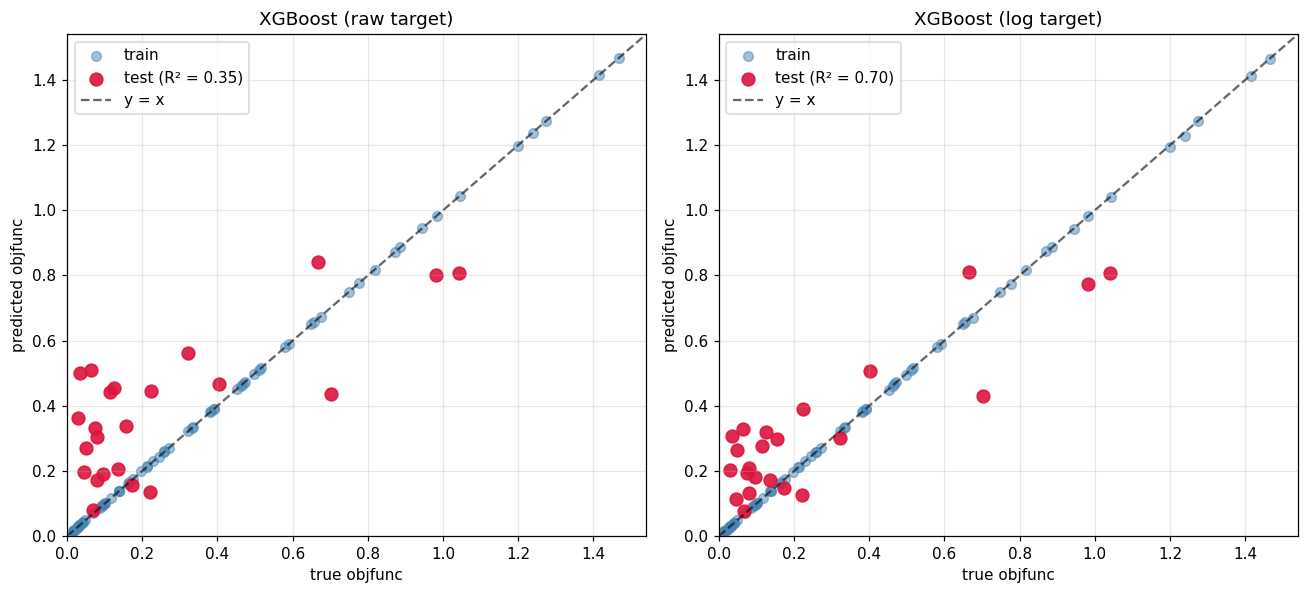

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
lim = [0, y.max() * 1.05]
for ax, name in zip(axes, ["XGBoost (raw target)", "XGBoost (log target)"]):
    m = fitted[name]
    ax.scatter(y_tr, m.predict(X_tr), s=40, alpha=0.5, color="steelblue", label="train")
    ax.scatter(y_te, m.predict(X_te), s=70, alpha=0.9, color="crimson",
               label=f"test (R² = {holdout[name]['test R²']:.2f})")
    ax.plot(lim, lim, "k--", alpha=0.6, label="y = x")
    ax.set(xlim=lim, ylim=lim, xlabel="true objfunc", ylabel="predicted objfunc", title=name)
    ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "parity_holdout.png", bbox_inches="tight")
plt.show()

Two warning signs: the XGBoost models fit the training data almost perfectly (train R² ≈ 1, i.e. they
over-fit), and the test set has only 23 points. How much does the test score depend on *which* 23 points
are held out?

In [8]:
split_scores = {"XGBoost (raw target)": [], "XGBoost (log target)": []}
for seed in range(50):
    a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.25, random_state=seed)
    for name in split_scores:
        m = make_models()[name].fit(a_tr, b_tr)
        split_scores[name].append(r2_score(b_te, m.predict(a_te)))

split_df = pd.DataFrame(split_scores).describe(percentiles=[0.1, 0.5, 0.9]).T
split_df[["min", "10%", "50%", "90%", "max"]].round(3)

,min,10%,50%,90%,max
XGBoost (raw target),-0.282,0.029,0.438,0.63,0.779
XGBoost (log target),-0.390,-0.017,0.369,0.68,0.814


The hold-out R² swings widely from one random split to another, so a single split is not a reliable
estimate. Repeated cross-validation is used instead.

## 4. Repeated 5-fold cross-validation

5-fold CV repeated 10 times with different shuffles (50 train/test evaluations per model).

In [9]:
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)

cv_rows, cv_r2 = {}, {}
for name, model in make_models().items():
    res = cross_validate(model, X, y, cv=cv, scoring=("r2", "neg_mean_absolute_error"))
    cv_r2[name] = res["test_r2"]
    cv_rows[name] = {
        "R² mean": res["test_r2"].mean(),
        "R² std": res["test_r2"].std(),
        "R² median": np.median(res["test_r2"]),
        "MAE mean": -res["test_neg_mean_absolute_error"].mean(),
    }

cv_df = pd.DataFrame(cv_rows).T.round(3)
cv_df

,R² mean,R² std,R² median,MAE mean
Mean predictor,-0.087,0.138,-0.028,0.295
Ridge regression,0.351,0.383,0.410,0.206
XGBoost (raw target),0.352,0.257,0.380,0.203
XGBoost (log target),0.332,0.249,0.344,0.184


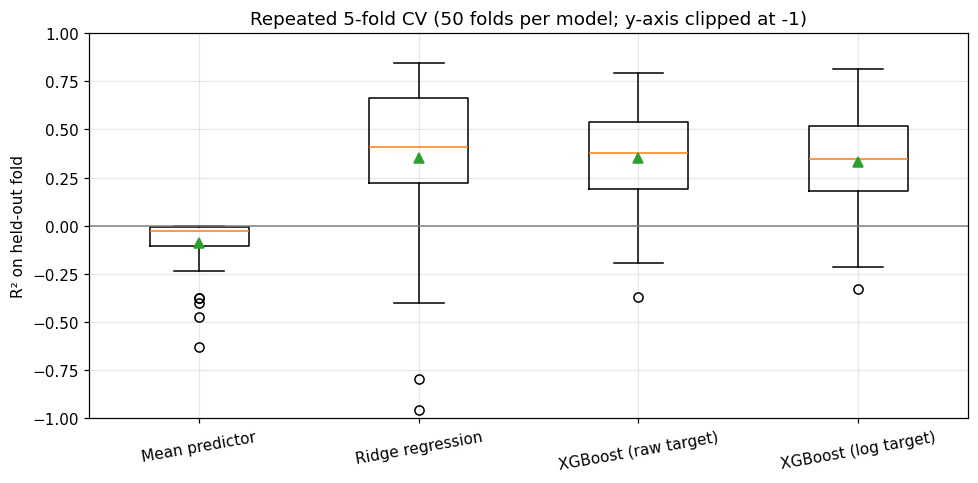

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(list(cv_r2.values()), showmeans=True)
ax.set_xticks(range(1, len(cv_r2) + 1), list(cv_r2.keys()), rotation=10)
ax.axhline(0, color="grey", lw=1)
ax.set_ylim(-1, 1)
ax.set(ylabel="R² on held-out fold", title="Repeated 5-fold CV (50 folds per model; y-axis clipped at -1)")
plt.tight_layout()
fig.savefig(FIG_DIR / "cv_r2.png", bbox_inches="tight")
plt.show()

## 5. Ranking quality — what matters for screening

In history matching the surrogate is used to decide **which candidates are worth simulating**, so the
order of its predictions matters more than their exact values. Using out-of-fold predictions
(each member is predicted by a model that never saw it), we measure

* **Spearman ρ** between predicted and true `objfunc`;
* **top-10 hit rate** — the share of the 10 members ranked best by the surrogate that truly belong to the
  best 25 % of the ensemble (a random choice gives 0.25 on average).

In [11]:
def ranking_metrics(model, n_repeats=10, top_k=10):
    best_quartile = np.quantile(y, 0.25)
    rho, hit = [], []
    for r in range(n_repeats):
        pred = cross_val_predict(model, X, y, cv=KFold(5, shuffle=True, random_state=r))
        rho.append(spearmanr(pred, y).correlation)
        top = np.argsort(pred)[:top_k]
        hit.append(np.mean(y[top] <= best_quartile))
    return {"Spearman ρ mean": np.mean(rho), "Spearman ρ std": np.std(rho), "top-10 hit rate": np.mean(hit)}


rank_df = pd.DataFrame({name: ranking_metrics(model)
                        for name, model in make_models().items()
                        if name != "Mean predictor"}).T.round(3)
rank_df

,Spearman ρ mean,Spearman ρ std,top-10 hit rate
Ridge regression,0.510,0.060,0.50
XGBoost (raw target),0.701,0.049,0.74
XGBoost (log target),0.700,0.027,0.76


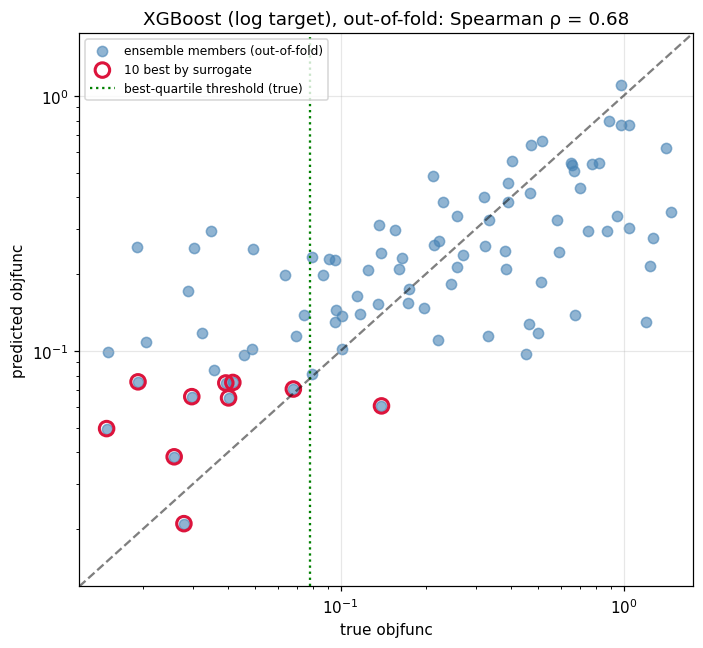

In [12]:
best_model = make_models()["XGBoost (log target)"]
oof = cross_val_predict(best_model, X, y, cv=KFold(5, shuffle=True, random_state=SEED))
rho = spearmanr(oof, y).correlation
top10 = np.argsort(oof)[:10]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y, oof, s=45, alpha=0.6, color="steelblue", label="ensemble members (out-of-fold)")
ax.scatter(y[top10], oof[top10], s=90, facecolors="none", edgecolors="crimson", lw=2,
           label="10 best by surrogate")
ax.axvline(np.quantile(y, 0.25), color="green", ls=":", label="best-quartile threshold (true)")
lims = [min(y.min(), oof.min()) * 0.8, max(y.max(), oof.max()) * 1.2]
ax.plot(lims, lims, "k--", alpha=0.5)
ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel="true objfunc", ylabel="predicted objfunc",
       title=f"XGBoost (log target), out-of-fold: Spearman ρ = {rho:.2f}")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "oof_ranking.png", bbox_inches="tight")
plt.show()

## 6. Which parameters matter?

Permutation importance measured on **held-out** folds (5-fold CV, 20 permutations per feature): how much
the MAE of the log-target XGBoost surrogate grows when one parameter is randomly shuffled.

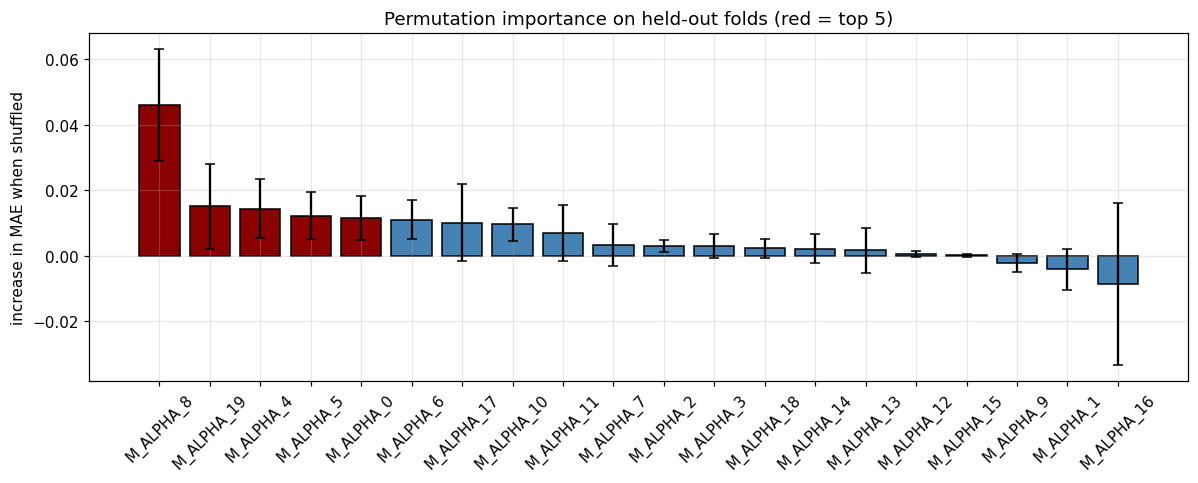

,mean,std
M_ALPHA_8,0.0459,0.0171
M_ALPHA_19,0.0150,0.0131
M_ALPHA_4,0.0144,0.0091
M_ALPHA_5,0.0122,0.0073
M_ALPHA_0,0.0115,0.0066


In [13]:
imp = []
for tr, te in KFold(5, shuffle=True, random_state=SEED).split(X):
    m = make_models()["XGBoost (log target)"].fit(X[tr], y[tr])
    r = permutation_importance(m, X[te], y[te], scoring="neg_mean_absolute_error",
                               n_repeats=20, random_state=SEED)
    imp.append(r.importances_mean)

imp = pd.DataFrame(imp, columns=feature_cols)
importance = pd.DataFrame({"mean": imp.mean(), "std": imp.std()}).sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
colors = ["darkred" if i < 5 else "steelblue" for i in range(len(importance))]
ax.bar(importance.index, importance["mean"], yerr=importance["std"], color=colors,
       edgecolor="black", capsize=3)
ax.set(ylabel="increase in MAE when shuffled", title="Permutation importance on held-out folds (red = top 5)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
fig.savefig(FIG_DIR / "feature_importance.png", bbox_inches="tight")
plt.show()

importance.head(5).round(4)

## 7. Computational speed-up

Simulation wall-clock times are taken from the run logs of the same history-matching project
(`data/simulation_runtimes.csv`, single workstation). Surrogate times are measured here.

In [14]:
runtimes = pd.read_csv(DATA_DIR / "simulation_runtimes.csv")
t_sim = runtimes["wall_time_s"].median()

final_model = make_models()["XGBoost (log target)"]
t0 = time.perf_counter()
final_model.fit(X, y)
t_fit = time.perf_counter() - t0

x_one = X[:1]
single = []
for _ in range(200):
    t0 = time.perf_counter()
    final_model.predict(x_one)
    single.append(time.perf_counter() - t0)
t_single = float(np.median(single))

rng = np.random.default_rng(SEED)
candidates = rng.uniform(X.min(axis=0), X.max(axis=0), size=(10_000, X.shape[1]))
t0 = time.perf_counter()
final_model.predict(candidates)
t_batch = (time.perf_counter() - t0) / len(candidates)

speed = pd.DataFrame({
    "time per evaluation, s": [t_sim, t_single, t_batch],
    "speed-up vs simulation": [1.0, t_sim / t_single, t_sim / t_batch],
}, index=["full simulation (median of %d runs)" % len(runtimes),
          "surrogate, single prediction", "surrogate, batch of 10 000"])
print(f"Simulation time: median {t_sim:.0f} s (range {runtimes.wall_time_s.min()}–{runtimes.wall_time_s.max()} s)")
print(f"Surrogate training time on all 92 members: {t_fit:.2f} s")
speed_view = speed.copy()
speed_view["time per evaluation, s"] = speed_view["time per evaluation, s"].map("{:.2e}".format)
speed_view["speed-up vs simulation"] = speed_view["speed-up vs simulation"].map("{:,.0f}×".format)
speed_view

Simulation time: median 13 s (range 10–18 s)
Surrogate training time on all 92 members: 0.10 s


,"time per evaluation, s",speed-up vs simulation
full simulation (median of 115 runs),1.30e+01,1×
"surrogate, single prediction",4.88e-04,"26,664×"
"surrogate, batch of 10 000",1.65e-06,"7,857,569×"


The speed-up applies to each *additional* evaluation. Building the surrogate still requires the
92 training simulations (about 92 × 13 s ≈ 20 minutes on one workstation for this small model).

## 8. Conclusions

1. **Accuracy.** An XGBoost surrogate trained on 92 ES-MDA ensemble members explains about a third of the
   variance of the history-matching objective in repeated 5-fold cross-validation (R² ≈ 0.33–0.35).
   Its mean absolute error (≈ 0.18–0.20) is about 35–40 % lower than that of the mean predictor (≈ 0.30).
2. **The single hold-out split was optimistic.** In the original split the log transform raised test R²
   from about 0.35 to 0.70, but across 50 random splits the hold-out R² ranges from below 0 to about 0.8,
   and in repeated cross-validation the log transform does not increase R². What it does improve is the
   mean absolute error (≈ 0.203 → 0.184, about −9 %) and the stability of the ranking.
3. **Screening value.** Out-of-fold, the surrogate orders the ensemble members well (Spearman ρ ≈ 0.70),
   and about three out of four of its 10 best-ranked candidates truly belong to the best quartile
   (random choice: 0.25; ridge regression: 0.50). A linear model reaches a similar R² but ranks much worse
   (ρ ≈ 0.51), so the non-linear model is what makes the surrogate useful for selecting candidates.
4. **Parameter importance.** One variable, `M_ALPHA_8`, dominates the misfit (permutation importance about
   three times that of the next one), followed by `M_ALPHA_19`, `M_ALPHA_4`, `M_ALPHA_5` and `M_ALPHA_0`.
5. **Cost.** One surrogate evaluation takes under a millisecond versus ≈ 13 s for a simulation run of this
   model (a speed-up of the order of 10⁴ per evaluation), after a one-time cost of 92 training simulations.

### Limitations

* Small data set (92 members) from a single synthetic model; the results may not transfer to real fields or
  to other parameterisations.
* The XGBoost models over-fit (train R² ≈ 1). Hyper-parameters were deliberately not tuned on so few samples;
  regularisation with nested cross-validation is a natural next step.
* All members come from one ensemble-smoother run, so they cover only part of the parameter space; the
  surrogate should not be trusted far outside the explored region.
* Simulation times refer to a small model on one workstation; for full-field models the speed-up would be
  larger.

### Next steps

* Use the surrogate inside an optimisation / active-learning loop: propose candidates, simulate only the most
  promising ones, retrain.
* Compare with Gaussian-process surrogates, which also provide uncertainty estimates.
* Predict well-level misfit components instead of a single scalar objective.